# الدرس 4: Decision Trees و Random Forest — الإنتروبيا وBagging

**الهدف:**
1. اشتقاق الإنتروبيا (Entropy) من نظرية المعلومات — القياس الرياضي لـ "عدم اليقين".
2. اشتقاق Information Gain — كيف تقرر الشجرة أين تقسّم البيانات.
3. بناء Decision Tree من الصفر بالكامل (recursive splitting).
4. اشتقاق Bagging (Bootstrap Aggregating) وليش يقلل التباين (variance) رياضيًا.
5. بناء Random Forest ومقارنة مع sklearn.

> هذا أول خوارزمية غير بارامترية (non-parametric) بمعنى مختلف عن kNN — الشجرة تبني هيكلها الخاص (structure) بناءً على البيانات، بدل ما تحسب مسافات فقط.

## 1. الإنتروبيا (Entropy) — قياس رياضي لعدم اليقين

جاءت هذه الفكرة من عالم المعلومات كلود شانون (Claude Shannon). السؤال: كيف نقيس "مدى فوضوية" (impurity) مجموعة بيانات من حيث الأصناف؟

لو عندنا متغير عشوائي $Y$ يأخذ قيم $\{1, 2, ..., K\}$ باحتمالات $p_1, p_2, ..., p_K$، الإنتروبيا تُعرَّف:

$$H(Y) = -\sum_{k=1}^{K} p_k \log_2(p_k)$$

**الحدس:** $-\log_2(p_k)$ يمثل "كمية المعلومات" (بالبت) اللي تحصل عليها لما تشاهد حدث احتماله $p_k$. حدث نادر (احتمال صغير) يحمل معلومة أكبر لو حصل. الإنتروبيا هي **المتوسط المرجّح** لكمية المعلومات هذي.

**حالات حديّة توضح الفكرة:**
- لو $p_1=1$ (كل البيانات من صنف واحد، "نقية" تمامًا): $H = -1\log_2(1) = 0$ → **لا يوجد عدم يقين إطلاقًا**.
- لو عندنا صنفين بنسبة $p_1=p_2=0.5$ (أقصى فوضى): $H = -0.5\log_2(0.5) -0.5\log_2(0.5) = 1$ → **أقصى عدم يقين ممكن** (لصنفين).

هذا بالضبط ليش نستخدمها كمقياس "نقاء" (purity) للعقدة في الشجرة.

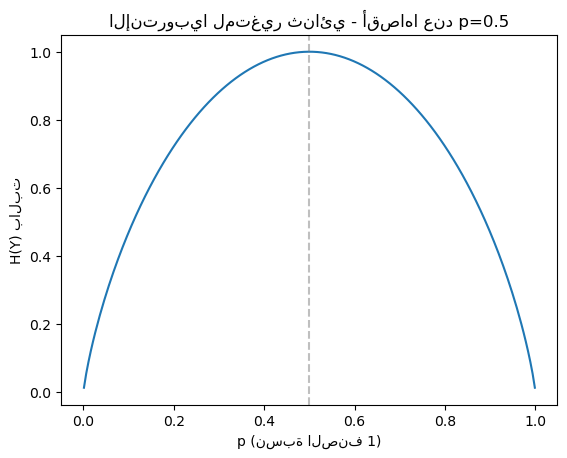

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def entropy_binary(p):
    if p == 0 or p == 1:
        return 0
    return -p * np.log2(p) - (1-p) * np.log2(1-p)

p_values = np.linspace(0.001, 0.999, 200)
entropies = [entropy_binary(p) for p in p_values]

plt.plot(p_values, entropies)
plt.xlabel('p (نسبة الصنف 1)'); plt.ylabel('H(Y) بالبت')
plt.title('الإنتروبيا لمتغير ثنائي - أقصاها عند p=0.5')
plt.axvline(0.5, color='gray', linestyle='--', alpha=0.5)
plt.show()

## 2. Information Gain — كيف تختار الشجرة نقطة التقسيم

لما نقسّم عقدة (node) $S$ إلى مجموعتين فرعيتين $S_{left}$ و $S_{right}$ بناءً على شرط على خاصية معينة (مثلاً $x_j \le t$)، نبي نعرف: **كم قلّلنا عدم اليقين بهذا التقسيم؟**

$$\text{Information Gain} = H(S) - \left[\frac{|S_{left}|}{|S|}H(S_{left}) + \frac{|S_{right}|}{|S|}H(S_{right})\right]$$

بمعنى آخر: (إنتروبيا العقدة الأم) ناقص (المتوسط المرجّح لإنتروبيا العقدتين الفرعيتين).

**خوارزمية بناء الشجرة (Greedy Algorithm):**
1. لكل خاصية $x_j$ ولكل نقطة تقسيم ممكنة $t$، احسب Information Gain.
2. اختر $(x_j, t)$ التي تعطي أعلى Information Gain.
3. قسّم البيانات، وكرر العملية بشكل تكراري (recursive) على كل فرع.
4. توقف عند شرط إيقاف (عمق أقصى، عدد عينات أدنى، أو إنتروبيا = 0).

هذا **greedy** — نختار أفضل تقسيم محلي في كل خطوة، بدون ضمان إنه الأمثل عالميًا (globally optimal). إيجاد الشجرة المثلى عالميًا هو مسألة NP-hard.

**ملاحظة:** sklearn افتراضيًا يستخدم **Gini Impurity** بدل الإنتروبيا (أسرع حسابيًا، نتائج مشابهة عمليًا تقريبًا دائمًا):
$$Gini(S) = 1 - \sum_{k=1}^{K} p_k^2$$

In [43]:
def entropy(y):
    """إنتروبيا مجموعة عينات y (متعددة الأصناف)"""
    if len(y) == 0:
        return 0
    counts = np.bincount(y)
    probabilities = counts / len(y)
    probabilities = probabilities[probabilities > 0]  # نتجاهل الأصفار (log(0) غير معرّف)
    return -np.sum(probabilities * np.log2(probabilities))

def information_gain(y, y_left, y_right):
    parent_entropy = entropy(y)
    n = len(y)
    weighted_child_entropy = (len(y_left)/n) * entropy(y_left) + (len(y_right)/n) * entropy(y_right)
    return parent_entropy - weighted_child_entropy

# اختبار سريع
y_test = np.array([0,0,0,0,1,1,1,1])
print('إنتروبيا مجموعة متوازنة تمامًا (4-4):', entropy(y_test))  # نتوقع 1.0

y_pure = np.array([1,1,1,1])
print('إنتروبيا مجموعة نقية:', entropy(y_pure))  # نتوقع 0.0

إنتروبيا مجموعة متوازنة تمامًا (4-4): 1.0
إنتروبيا مجموعة نقية: -0.0


## 3. بناء Decision Tree من الصفر

In [44]:
class Node:
    """عقدة في الشجرة - إما عقدة تقسيم (feature+threshold) أو عقدة ورقة (leaf) بقيمة تنبؤ"""
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value  # يوجد فقط في عقدة الورقة

    def is_leaf(self):
        return self.value is not None


class DecisionTreeClassifierScratch:
    def __init__(self, max_depth=10, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

    def fit(self, X, y):
        self.root = self._grow_tree(X, y, depth=0)

    def _best_split(self, X, y):
        best_gain = -1
        best_feature, best_threshold = None, None
        n_features = X.shape[1]

        for feature_idx in range(n_features):
            thresholds = np.unique(X[:, feature_idx])
            for t in thresholds:
                left_mask = X[:, feature_idx] <= t
                right_mask = ~left_mask
                if left_mask.sum() == 0 or right_mask.sum() == 0:
                    continue
                gain = information_gain(y, y[left_mask], y[right_mask])
                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature_idx
                    best_threshold = t

        return best_feature, best_threshold, best_gain

    def _grow_tree(self, X, y, depth):
        n_samples = len(y)
        n_classes = len(np.unique(y))

        # شروط التوقف
        if (depth >= self.max_depth or n_classes == 1 or n_samples < self.min_samples_split):
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        feature, threshold, gain = self._best_split(X, y)

        # لو ما فيه تقسيم يحسّن الوضع، نوقف
        if feature is None or gain <= 0:
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        left_child = self._grow_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._grow_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(feature=feature, threshold=threshold, left=left_child, right=right_child)

    def _traverse(self, x, node):
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse(x, node.left)
        return self._traverse(x, node.right)

    def predict(self, X):
        return np.array([self._traverse(x, self.root) for x in X])

print('الكلاس جاهز.')

الكلاس جاهز.


In [45]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

our_tree = DecisionTreeClassifierScratch(max_depth=5)
our_tree.fit(X_train, y_train)
our_preds = our_tree.predict(X_test)
our_accuracy = np.mean(our_preds == y_test)
print(f'دقة شجرتنا: {our_accuracy:.4f}')

sklearn_tree = DecisionTreeClassifier(max_depth=5, criterion='entropy', random_state=42)
sklearn_tree.fit(X_train, y_train)
sklearn_preds = sklearn_tree.predict(X_test)
sklearn_accuracy = np.mean(sklearn_preds == y_test)
print(f'دقة شجرة sklearn: {sklearn_accuracy:.4f}')

دقة شجرتنا: 1.0000
دقة شجرة sklearn: 1.0000


**ملاحظة:** ممكن تلاحظ فرق بسيط بين الدقّتين — هذا طبيعي لأن sklearn يستخدم تحسينات إضافية (زي معالجة التعادل بين thresholds بطريقة مختلفة قليلًا، أو ترتيب معالجة الخصائص). المهم إن **المنطق الأساسي مطابق** — وهذا ما يهمنا تعليميًا.

## 4. مشكلة Decision Trees: Overfitting الشديد

شجرة قرار واحدة بعمق كافٍ تقدر "تحفظ" بيانات التدريب بالكامل (كل ورقة تحتوي عينة واحدة) — إنتروبيا = 0 في كل مكان، لكن **تعميم كارثي** على بيانات جديدة. هذا **تباين عالٍ جدًا (high variance)**: تغيير بسيط في بيانات التدريب ينتج شجرة مختلفة تمامًا.

هنا يجي الحل: **Bagging (Bootstrap Aggregating)**.

## 5. اشتقاق Bagging — لماذا يقلل التباين رياضيًا؟

لدينا $B$ نموذج (شجرة) مستقلة تقريبًا، كل واحدة تدرّبت على عينة bootstrap مختلفة (سحب عشوائي بالتعويض من بيانات التدريب الأصلية). التوقع النهائي هو متوسط توقعاتها:

$$\hat{f}_{bag}(x) = \frac{1}{B}\sum_{b=1}^{B} \hat{f}_b(x)$$

**لماذا يقلل التباين؟** افترض كل نموذج $\hat{f}_b(x)$ له نفس التباين $\sigma^2$، ومترابطين ببعض بمعامل ارتباط $\rho$ (لأنهم تدربوا على بيانات متشابهة جزئيًا). تباين المتوسط:

$$\text{Var}(\hat{f}_{bag}) = \rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$$

**نقطتين مهمتين من هذي الصيغة:**
1. لو $B \to \infty$، الحد الثاني يتلاشى، ويبقى فقط $\rho\sigma^2$ — **يعني التباين ما يوصل صفر أبدًا**، بل يوصل حد أدنى يعتمد على الارتباط $\rho$ بين الأشجار.
2. **هذا بالضبط سبب وجود Random Forest**: لو قلّلنا $\rho$ (الارتباط بين الأشجار)، نقلل التباين أكثر! وهذا بالضبط وش يسويه Random Forest إضافة لـ bagging: **يختار عشوائيًا مجموعة فرعية من الخصائص (feature subsampling) عند كل تقسيم** — هذا يجبر الأشجار المختلفة تصير أقل تشابهًا وأقل ارتباطًا ببعض.

In [46]:
class RandomForestScratch:
    def __init__(self, n_trees=10, max_depth=5, max_features='sqrt'):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.max_features = max_features
        self.trees = []
        self.tree_features = []  # نخزن أي خصائص استخدمت كل شجرة

    def _bootstrap_sample(self, X, y):
        n_samples = X.shape[0]
        idxs = np.random.choice(n_samples, size=n_samples, replace=True)  # سحب بالتعويض
        return X[idxs], y[idxs]

    def fit(self, X, y):
        n_features = X.shape[1]
        if self.max_features == 'sqrt':
            n_selected = max(1, int(np.sqrt(n_features)))
        else:
            n_selected = n_features

        self.trees = []
        self.tree_features = []

        for _ in range(self.n_trees):
            X_sample, y_sample = self._bootstrap_sample(X, y)

            # اختيار عشوائي لمجموعة فرعية من الخصائص (هذا الفرق الأساسي عن bagging عادي)
            feature_idxs = np.random.choice(n_features, size=n_selected, replace=False)

            tree = DecisionTreeClassifierScratch(max_depth=self.max_depth)
            tree.fit(X_sample[:, feature_idxs], y_sample)

            self.trees.append(tree)
            self.tree_features.append(feature_idxs)

    def predict(self, X):
        # كل شجرة تتوقع باستخدام فقط الخصائص اللي دُرّبت عليها
        tree_preds = np.array([
            tree.predict(X[:, feats]) for tree, feats in zip(self.trees, self.tree_features)
        ])
        # تصويت أغلبي عبر الأشجار (لكل عينة)
        final_preds = []
        for i in range(X.shape[0]):
            votes = tree_preds[:, i]
            final_preds.append(Counter(votes).most_common(1)[0][0])
        return np.array(final_preds)

np.random.seed(42)
our_forest = RandomForestScratch(n_trees=20, max_depth=5)
our_forest.fit(X_train, y_train)
our_forest_preds = our_forest.predict(X_test)
our_forest_accuracy = np.mean(our_forest_preds == y_test)
print(f'دقة الغابة عندنا: {our_forest_accuracy:.4f}')

دقة الغابة عندنا: 1.0000


In [47]:
from sklearn.ensemble import RandomForestClassifier

sklearn_forest = RandomForestClassifier(n_estimators=20, max_depth=5, random_state=42)
sklearn_forest.fit(X_train, y_train)
sklearn_forest_accuracy = sklearn_forest.score(X_test, y_test)
print(f'دقة غابة sklearn: {sklearn_forest_accuracy:.4f}')

print()
print('مقارنة شاملة:')
print(f'  شجرة واحدة (عندنا):   {our_accuracy:.4f}')
print(f'  Random Forest (عندنا): {our_forest_accuracy:.4f}')
print(f'  Random Forest (sklearn): {sklearn_forest_accuracy:.4f}')

دقة غابة sklearn: 1.0000

مقارنة شاملة:
  شجرة واحدة (عندنا):   1.0000
  Random Forest (عندنا): 1.0000
  Random Forest (sklearn): 1.0000


## 6. تصور بصري: تأثير Bagging على استقرار حدود القرار

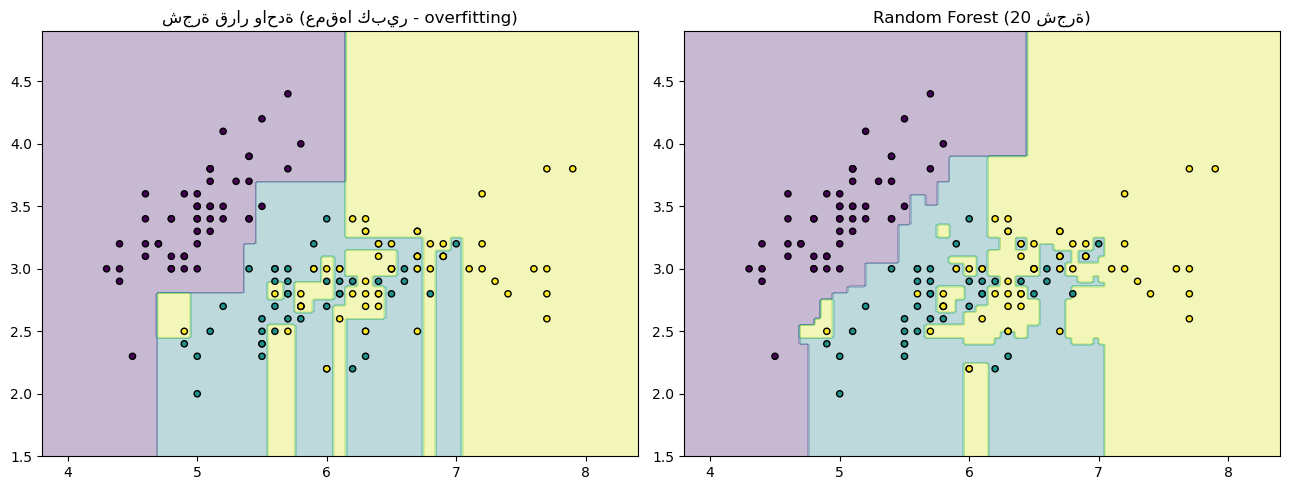

لاحظ: حدود الشجرة الواحدة متعرّجة جدًا وحادة (overfitting)
بينما حدود Random Forest أنعم وأكثر تعميمًا


In [48]:
# نستخدم خاصيتين فقط عشان نقدر نرسم
X2 = X[:, :2]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, [
    ('شجرة قرار واحدة (عمقها كبير - overfitting)', DecisionTreeClassifier(max_depth=None, random_state=42)),
    ('Random Forest (20 شجرة)', RandomForestClassifier(n_estimators=20, random_state=42))
]):
    model.fit(X2_train, y2_train)

    x_min, x_max = X2[:, 0].min()-0.5, X2[:, 0].max()+0.5
    y_min, y_max = X2[:, 1].min()-0.5, X2[:, 1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax.scatter(X2[:,0], X2[:,1], c=y, cmap='viridis', edgecolor='k', s=20)
    ax.set_title(name)

plt.tight_layout()
plt.show()

print('لاحظ: حدود الشجرة الواحدة متعرّجة جدًا وحادة (overfitting)')
print('بينما حدود Random Forest أنعم وأكثر تعميمًا')

## ملخص

| المفهوم | المعادلة | الدور |
|---|---|---|
| Entropy | $-\sum p_k\log_2 p_k$ | قياس عدم اليقين/الفوضى في عقدة |
| Information Gain | $H(parent) - \sum \frac{n_i}{n}H(child_i)$ | معيار اختيار أفضل تقسيم |
| Bagging | $\hat f_{bag}=\frac1B\sum \hat f_b$ | تقليل التباين بمتوسط نماذج مستقلة |
| Random Forest | Bagging + عشوائية الخصائص | تقليل الارتباط $\rho$ بين الأشجار → تباين أقل

## تمارين لك

1. عدّل الكود عشان يستخدم **Gini Impurity** بدل الإنتروبيا (`1 - sum(p_k^2)`)، وقارن النتائج. هل الفرق كبير عمليًا؟
2. جرّب `max_depth` مختلفة (1, 3, 5, 10, None) على شجرة واحدة، وارسم منحنى الدقة على train مقابل test لكل عمق — هذا يوريك overfitting بصريًا (شبيه بمنحنى k في kNN).
3. اشتق بنفسك: لو $\rho=1$ (كل الأشجار مطابقة تمامًا لبعضها)، بيّن أن صيغة تباين bagging ترجع لـ $\sigma^2$ نفسه (يعني bagging ما يفيد شي لو الأشجار كلها متطابقة) — وهذا يفسر ليش Random Forest يتفوق على Bagging العادي (لأنه يقلل $\rho$ فعليًا عبر عشوائية الخصائص).

**الدرس الجاي:** SVM — هنا بنشتق مفهوم الـ margin، ونتعرف على Lagrange duality والـ kernel trick، أحد أجمل الأفكار الرياضية في ML الكلاسيكي.

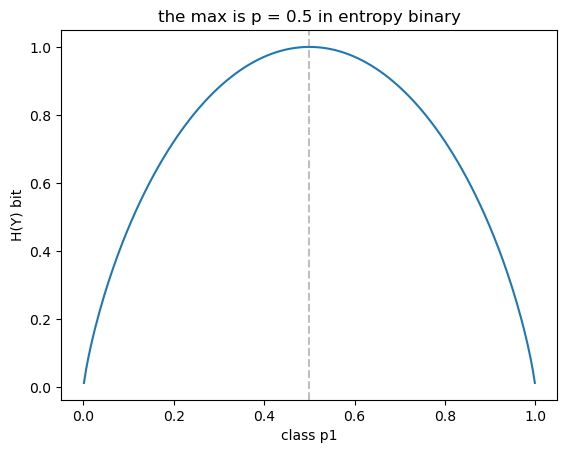

In [49]:
import numpy as np 
import matplotlib.pyplot as plt
from collections import Counter

def entropy_binary(p):
    if p == 0 or p == 1:
        return 0
    return -p * np.log2(p) - (1 - p) * np.log2(1 - p)

p_values = np.linspace(0.001 , 0.999 , 200)
entropies = [entropy_binary(x) for x in p_values]

plt.plot(p_values , entropies)
plt.xlabel("class p1"); plt.ylabel("H(Y) bit")
plt.title("the max is p = 0.5 in entropy binary")
plt.axvline(0.5 , color='grey' , linestyle='--' , alpha=0.5)
plt.show()

In [50]:
def entropy(y):
    """إنتروبيا مجموعة عينات y (متعددة الأصناف)"""
    if len(y) == 0:
        return 0
    counts = np.bincount(y)
    probabilities = counts / len(y)
    probabilities = probabilities[probabilities > 0]  # نتجاهل الأصفار (log(0) غير معرّف)
    return -np.sum(probabilities * np.log2(probabilities))

def information_gain(y, y_left, y_right):
    parent_entropy = entropy(y)
    n = len(y)
    weighted_child_entropy = (len(y_left)/n) * entropy(y_left) + (len(y_right)/n) * entropy(y_right)
    return parent_entropy - weighted_child_entropy

# اختبار سريع
y_test = np.array([0,0,0,0,1,1,1,1])
print('إنتروبيا مجموعة متوازنة تمامًا (4-4):', entropy(y_test))  # نتوقع 1.0

y_pure = np.array([1,1,1,1])
print('إنتروبيا مجموعة نقية:', entropy(y_pure))  # نتوقع 0.0

إنتروبيا مجموعة متوازنة تمامًا (4-4): 1.0
إنتروبيا مجموعة نقية: -0.0


In [51]:
class Node:
    """عقدة في الشجرة - إما عقدة تقسيم (feature+threshold) أو عقدة ورقة (leaf) بقيمة تنبؤ"""
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value  # يوجد فقط في عقدة الورقة

    def is_leaf(self):
        return self.value is not None


class DecisionTreeClassifierScratch:
    def __init__(self, max_depth=10, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

    def fit(self, X, y):
        self.root = self._grow_tree(X, y, depth=0)

    def print_tree(self, node=None, depth=0):
        if node is None:
            node = self.root
    
        indent = "  " * depth
    
        if node.is_leaf():
            print(f"{indent}Leaf -> class = {node.value}")
            return
    
        print(
            f"{indent}X[{node.feature}] <= {node.threshold:.4f}"
        )
    
        print(f"{indent}├── Left")
        self.print_tree(node.left, depth + 1)
    
        print(f"{indent}└── Right")
        self.print_tree(node.right, depth + 1)

    def _best_split(self, X, y):
    
        best_gain = -1
        best_feature = None
        best_threshold = None
    
        n_features = X.shape[1]
    
        for feature_idx in range(n_features):
    
            thresholds = np.unique(X[:, feature_idx])
    
            for t in thresholds:

                left_mask = X[:, feature_idx] <= t
                right_mask = ~left_mask
    
                if left_mask.sum() == 0 or right_mask.sum() == 0:
                    continue
    
                gain = information_gain(
                    y,
                    y[left_mask],
                    y[right_mask]
                )
    
                # print(
                #     f"feature={feature_idx}, "
                #     f"threshold={t:.4f}, "
                #     f"gain={gain:.6f}"
                # )
    
                if gain > best_gain:
    
                    best_gain = gain
                    best_feature = feature_idx
                    best_threshold = t
    
        # print("\nBEST SPLIT:")
        # print(
        #     f"feature={best_feature}, "
        #     f"threshold={best_threshold:.4f}, "
        #     f"gain={best_gain:.6f}"
        # )
    
        return best_feature, best_threshold, best_gain

    # def _best_split(self, X, y):
    #     best_gain = -1
    #     best_feature, best_threshold = None, None
    #     n_features = X.shape[1]

    #     for feature_idx in range(n_features):
    #         thresholds = np.unique(X[:, feature_idx])
    #         for t in thresholds:
    #             left_mask = X[:, feature_idx] <= t
    #             right_mask = ~left_mask
    #             if left_mask.sum() == 0 or right_mask.sum() == 0:
    #                 continue
    #             gain = information_gain(y, y[left_mask], y[right_mask])
    #             if gain > best_gain:
    #                 best_gain = gain
    #                 best_feature = feature_idx
    #                 best_threshold = t

    #     return best_feature, best_threshold, best_gain

    def _grow_tree(self, X, y, depth):
        n_samples = len(y)
        n_classes = len(np.unique(y))

        # شروط التوقف
        if (depth >= self.max_depth or n_classes == 1 or n_samples < self.min_samples_split):
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        feature, threshold, gain = self._best_split(X, y)

        # لو ما فيه تقسيم يحسّن الوضع، نوقف
        if feature is None or gain <= 0:
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        left_child = self._grow_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._grow_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(feature=feature, threshold=threshold, left=left_child, right=right_child)

    def _traverse(self, x, node):
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse(x, node.left)
        return self._traverse(x, node.right)

    def predict(self, X):
        return np.array([self._traverse(x, self.root) for x in X])

print('الكلاس جاهز.')

الكلاس جاهز.


X[2] <= 1.9000
├── Left
  Leaf -> class = 0
└── Right
  X[2] <= 4.7000
  ├── Left
    X[3] <= 1.6000
    ├── Left
      Leaf -> class = 1
    └── Right
      Leaf -> class = 2
  └── Right
    X[3] <= 1.7000
    ├── Left
      X[2] <= 4.9000
      ├── Left
        Leaf -> class = 1
      └── Right
        X[3] <= 1.5000
        ├── Left
          Leaf -> class = 2
        └── Right
          Leaf -> class = 1
    └── Right
      X[2] <= 4.8000
      ├── Left
        X[0] <= 5.9000
        ├── Left
          Leaf -> class = 1
        └── Right
          Leaf -> class = 2
      └── Right
        Leaf -> class = 2
دقة شجرتنا: 1.0000
دقة شجرة sklearn: 1.0000


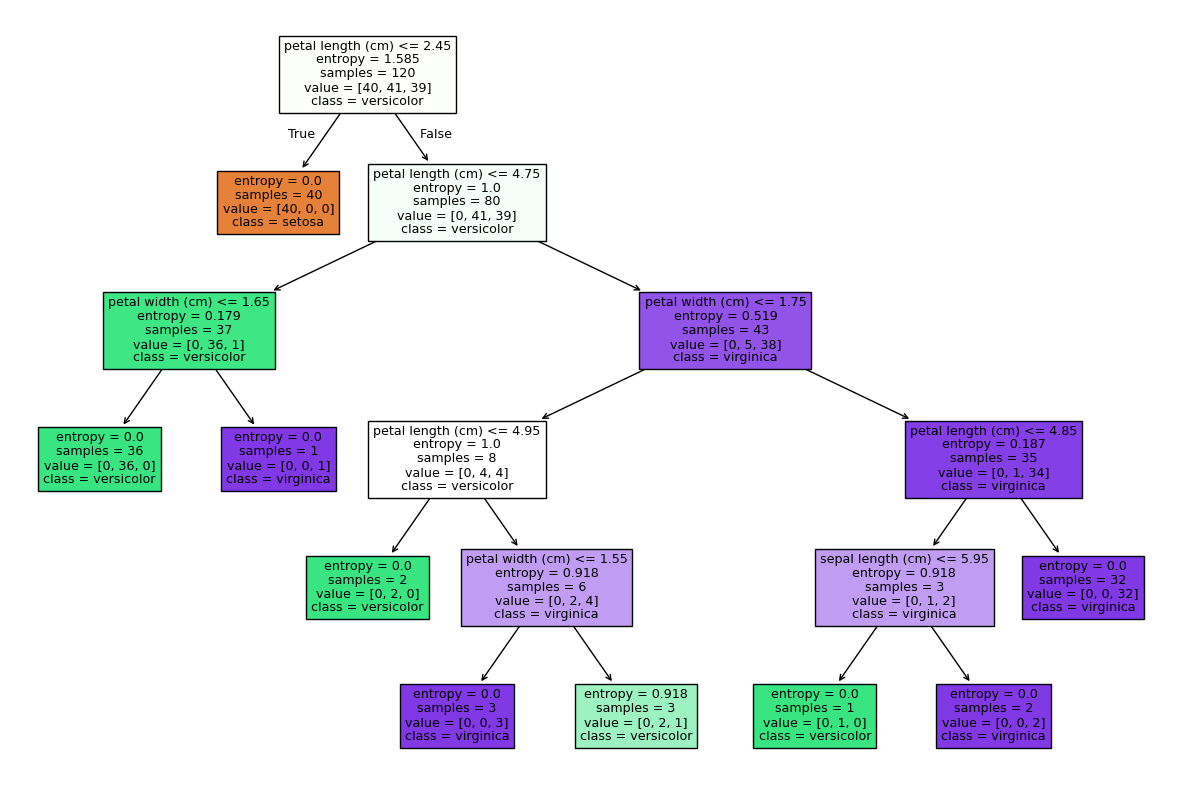

In [52]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

our_tree = DecisionTreeClassifierScratch(max_depth=5)
our_tree.fit(X_train, y_train)
our_preds = our_tree.predict(X_test)
our_tree.print_tree()
our_accuracy = np.mean(our_preds == y_test)
print(f'دقة شجرتنا: {our_accuracy:.4f}')

sklearn_tree = DecisionTreeClassifier(max_depth=5, criterion='entropy', random_state=42)
sklearn_tree.fit(X_train, y_train)
sklearn_preds = sklearn_tree.predict(X_test)
sklearn_accuracy = np.mean(sklearn_preds == y_test)
print(f'دقة شجرة sklearn: {sklearn_accuracy:.4f}')
plt.figure(figsize=(15 , 10))
plot_tree(
    sklearn_tree,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True
)

plt.show()

In [53]:
for depth in [1, 2, 3 ,4 , 5 , 10]:
    tree = DecisionTreeClassifierScratch(max_depth=depth)

    tree.fit(X_train , y_train)

    train_preds = tree.predict(X_train)
    test_preds = tree.predict(X_test)

    train_acc = np.mean(train_preds == y_train)
    test_acc = np.mean(test_preds == y_test)

    print(
        f"depth{depth:2d} | "
        f"train={train_acc:.4f} |"
        f"test={test_acc:.4f}"
    )

    

depth 1 | train=0.6750 |test=0.6333
depth 2 | train=0.9500 |test=0.9667
depth 3 | train=0.9583 |test=0.9667
depth 4 | train=0.9750 |test=1.0000
depth 5 | train=0.9917 |test=1.0000
depth10 | train=1.0000 |test=1.0000


In [54]:
class RandomForestScratch:
    def __init__(self, n_trees=10, max_depth=5, max_features='sqrt'):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.max_features = max_features
        self.trees = []
        self.tree_features = []  # نخزن أي خصائص استخدمت كل شجرة

    def _bootstrap_sample(self, X, y):
        n_samples = X.shape[0]
        idxs = np.random.choice(n_samples, size=n_samples, replace=True)  # سحب بالتعويض
        return X[idxs], y[idxs]

    def fit(self, X, y):
        n_features = X.shape[1]
        if self.max_features == 'sqrt':
            n_selected = max(1, int(np.sqrt(n_features)))
        else:
            n_selected = n_features

        self.trees = []
        self.tree_features = []

        for _ in range(self.n_trees):
            X_sample, y_sample = self._bootstrap_sample(X, y)

            # اختيار عشوائي لمجموعة فرعية من الخصائص (هذا الفرق الأساسي عن bagging عادي)
            feature_idxs = np.random.choice(n_features, size=n_selected, replace=False)

            tree = DecisionTreeClassifierScratch(max_depth=self.max_depth)
            tree.fit(X_sample[:, feature_idxs], y_sample)

            self.trees.append(tree)
            self.tree_features.append(feature_idxs)

    def predict(self, X):
        # if we have 3 tree and we need to choose 4 features
        # the result of all one tree if this if we give 5 sample for testing and we have 2 classe 0 and 1 
        # of any tree give result 1 tree [ 0 , 1 ,0 , 1 , 1] , 2 tree [ 1 ,1 ,1 ,1, 1] , 3 tree [ 0 , 0 , 0 , 1, ,1 ]
        #                                 s1  s2  s3  s4 s5           s1  s2  s3  s4 s5          s1  s2  s3  s4 s5
        # me we need to make votes for every sample that mean we need to get for every tree the result for every sample
        # example for the first sample [ 0 , 1 ,0 ] the second sample [1 , 1, 0]
        #                            tree1 tree2 tree3              tree1 tree2 tree3
        # know we do the votes for the sample 1 the votes result is 0  and for the sample 2 the votes result is 1
        # كل شجرة تتوقع باستخدام فقط الخصائص اللي دُرّبت عليها
        tree_preds = np.array([
            tree.predict(X[:, feats]) for tree, feats in zip(self.trees, self.tree_features)
        ])
        # we have the shape of the tree_preds is (3, 4) that mean 3 tree and 4 features 
        # me I need to get form every tree the first i and make the votes
        # that mean I will use loop the every number of test data because here we use just 5 
        # the loop start from 0 to 4 and for every iteration we get the the i result for every tree and make votes
        # تصويت أغلبي عبر الأشجار (لكل عينة)
        final_preds = []
        for i in range(X.shape[0]):
            votes = tree_preds[:, i]
            final_preds.append(Counter(votes).most_common(1)[0][0])
        return np.array(final_preds)

np.random.seed(42)
our_forest = RandomForestScratch(n_trees=20, max_depth=5)
our_forest.fit(X_train, y_train)
our_forest_preds = our_forest.predict(X_test)
our_forest_accuracy = np.mean(our_forest_preds == y_test)
print(f'دقة الغابة عندنا: {our_forest_accuracy:.4f}')


دقة الغابة عندنا: 1.0000


In [55]:
class Node:
    """عقدة في الشجرة - إما عقدة تقسيم (feature+threshold) أو عقدة ورقة (leaf) بقيمة تنبؤ"""
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value  # يوجد فقط في عقدة الورقة

    def is_leaf(self):
        return self.value is not None

class DecisionTreeClassifierScratch:
    def __init__(self, max_depth=10, min_samples_split=2 , max_features="sqrt"):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features

    def fit(self, X, y):
        self.root = self._grow_tree(X, y, depth=0)

    def print_tree(self, node=None, depth=0):
        if node is None:
            node = self.root
    
        indent = "  " * depth
    
        if node.is_leaf():
            print(f"{indent}Leaf -> class = {node.value}")
            return
    
        print(
            f"{indent}X[{node.feature}] <= {node.threshold:.4f}"
        )
    
        print(f"{indent}├── Left")
        self.print_tree(node.left, depth + 1)
    
        print(f"{indent}└── Right")
        self.print_tree(node.right, depth + 1)

    
    def _best_split(self, X, y):
    
        best_gain = -1
        best_feature = None
        best_threshold = None
        
        n_features = X.shape[1]
        if self.max_features == "sqrt":
            n_selected = max(1 , int(np.sqrt(n_features)))
        elif isinstance(self.max_features , int):
            n_selected = min(self.max_features ,n_features)
        else:
            n_selected = n_features

        feature_indices = np.random.choice(
            n_features,
            size=n_selected,
            replace=False
        )
        for feature_idx in range(n_features):
    
            thresholds = np.unique(X[:, feature_idx])
    
            for t in thresholds:

                left_mask = X[:, feature_idx] <= t
                right_mask = ~left_mask
    
                if left_mask.sum() == 0 or right_mask.sum() == 0:
                    continue
    
                gain = information_gain(
                    y,
                    y[left_mask],
                    y[right_mask]
                )
    
                # print(
                #     f"feature={feature_idx}, "
                #     f"threshold={t:.4f}, "
                #     f"gain={gain:.6f}"
                # )
    
                if gain > best_gain:
    
                    best_gain = gain
                    best_feature = feature_idx
                    best_threshold = t
    
        # print("\nBEST SPLIT:")
        # print(
        #     f"feature={best_feature}, "
        #     f"threshold={best_threshold:.4f}, "
        #     f"gain={best_gain:.6f}"
        # )
    
        return best_feature, best_threshold, best_gain

    # def _best_split(self, X, y):
    #     best_gain = -1
    #     best_feature, best_threshold = None, None
    #     n_features = X.shape[1]

    #     for feature_idx in range(n_features):
    #         thresholds = np.unique(X[:, feature_idx])
    #         for t in thresholds:
    #             left_mask = X[:, feature_idx] <= t
    #             right_mask = ~left_mask
    #             if left_mask.sum() == 0 or right_mask.sum() == 0:
    #                 continue
    #             gain = information_gain(y, y[left_mask], y[right_mask])
    #             if gain > best_gain:
    #                 best_gain = gain
    #                 best_feature = feature_idx
    #                 best_threshold = t

    #     return best_feature, best_threshold, best_gain

    def _grow_tree(self, X, y, depth):
        n_samples = len(y)
        n_classes = len(np.unique(y))

        # شروط التوقف
        if (depth >= self.max_depth or n_classes == 1 or n_samples < self.min_samples_split):
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        feature, threshold, gain = self._best_split(X, y)

        # لو ما فيه تقسيم يحسّن الوضع، نوقف
        if feature is None or gain <= 0:
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        left_child = self._grow_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._grow_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(feature=feature, threshold=threshold, left=left_child, right=right_child)

    def _traverse(self, x, node):
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse(x, node.left)
        return self._traverse(x, node.right)

    def predict(self, X):
        return np.array([self._traverse(x, self.root) for x in X])

print('الكلاس جاهز.')

np.random.seed(42)

tree = DecisionTreeClassifierScratch(
    max_depth=5,
    max_features="sqrt"
)

tree.fit(X_train, y_train)

preds = tree.predict(X_test)

accuracy = np.mean(preds == y_test)
print(f"Decision Tree accuracy: {accuracy:.4f}")

الكلاس جاهز.
Decision Tree accuracy: 1.0000


In [63]:

class RandomForestScratch:
    def __init__(self, n_trees=10, max_depth=5, max_features="sqrt"):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.max_features = max_features
        self.trees = []

    def predict_each_tree(self, X):
        return np.array([
            tree.predict(X)
            for tree in self.trees
        ])

    def _bootstrap_sample(self, X, y):
        n_samples = X.shape[0]

        idxs = np.random.choice(
            n_samples,
            size=n_samples,
            replace=True
        )

        return X[idxs], y[idxs]

    def fit(self, X, y):
        self.trees = []

        for _ in range(self.n_trees):
            # 1. Create a bootstrap dataset
            X_sample, y_sample = self._bootstrap_sample(X, y)

            # 2. Create a tree with random feature selection
            tree = DecisionTreeClassifierScratch(
                max_depth=self.max_depth,
                max_features=self.max_features
            )

            # 3. Train the tree
            tree.fit(X_sample, y_sample)

            # 4. Store the trained tree
            self.trees.append(tree)

    def predict(self, X):
        # Each row represents a tree; each column a sample
        tree_preds = np.array([
            tree.predict(X) for tree in self.trees
        ])

        # Majority vote for each sample
        final_preds = []

        for i in range(X.shape[0]):
            votes = tree_preds[:, i]
            prediction = Counter(votes).most_common(1)[0][0]
            final_preds.append(prediction)

        return np.array(final_preds)

np.random.seed(42)

our_forest = RandomForestScratch(
    n_trees=20,
    max_depth=5,
    max_features="sqrt"
)

our_forest.fit(X_train, y_train)

our_forest_preds = our_forest.predict(X_test)

our_forest_accuracy = np.mean(
    our_forest_preds == y_test
)

print(f"Random Forest accuracy: {our_forest_accuracy:.4f}")

Random Forest accuracy: 1.0000


In [64]:
for n in [1, 5, 10, 20, 50, 100]:
    np.random.seed(42)

    forest = RandomForestScratch(
        n_trees=n,
        max_depth=5,
        max_features="sqrt"
    )

    forest.fit(X_train, y_train)
    preds = forest.predict(X_test)
    accuracy = np.mean(preds == y_test)

    print(f"Trees: {n:3d} | Accuracy: {accuracy:.4f}")

Trees:   1 | Accuracy: 0.9667
Trees:   5 | Accuracy: 1.0000
Trees:  10 | Accuracy: 1.0000
Trees:  20 | Accuracy: 1.0000
Trees:  50 | Accuracy: 1.0000
Trees: 100 | Accuracy: 1.0000


In [65]:
for seed in [0, 1, 2, 3, 4, 42, 100]:
    np.random.seed(seed)

    forestt = RandomForestScratch(
        n_trees=20,
        max_depth=5,
        max_features="sqrt"
    )

    forestt.fit(X_train, y_train)
    preds = forestt.predict(X_test)
    accuracy = np.mean(preds == y_test)

    print(f"Seed: {seed:3d} | Accuracy: {accuracy:.4f}")

Seed:   0 | Accuracy: 1.0000
Seed:   1 | Accuracy: 1.0000
Seed:   2 | Accuracy: 1.0000
Seed:   3 | Accuracy: 1.0000
Seed:   4 | Accuracy: 1.0000
Seed:  42 | Accuracy: 1.0000
Seed: 100 | Accuracy: 1.0000


In [66]:
train_preds = our_forest.predict(X_train)
test_preds = our_forest.predict(X_test)

train_acc = np.mean(train_preds == y_train)
test_acc = np.mean(test_preds == y_test)

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")

Train Accuracy: 1.0000
Test Accuracy:  1.0000


In [67]:
for mf in [1, 2, "sqrt", None]:
    np.random.seed(42)

    forest = RandomForestScratch(
        n_trees=50,
        max_depth=5,
        max_features=mf
    )

    forest.fit(X_train, y_train)

    train_acc = np.mean(
        forest.predict(X_train) == y_train
    )
    test_acc = np.mean(
        forest.predict(X_test) == y_test
    )

    print(
        f"max_features={mf!s:4} | "
        f"Train={train_acc:.4f} | "
        f"Test={test_acc:.4f}"
    )

max_features=1    | Train=1.0000 | Test=1.0000
max_features=2    | Train=1.0000 | Test=1.0000
max_features=sqrt | Train=1.0000 | Test=1.0000
max_features=None | Train=1.0000 | Test=1.0000


In [68]:
for mf in [1, 2, "sqrt", None]:
    np.random.seed(42)

    forest = RandomForestScratch(
        n_trees=50,
        max_depth=5,
        max_features=mf
    )

    forest.fit(X_train, y_train)

    tree_preds = forest.predict_each_tree(X_test)

    # نسبة العينات التي تتفق عليها كل الأشجار
    agreement = np.mean(
        tree_preds == tree_preds[0:1, :]
    )

    print(
        f"max_features={mf!s:4} | "
        f"Agreement with tree 0: {agreement:.4f}"
    )

max_features=1    | Agreement with tree 0: 0.9620
max_features=2    | Agreement with tree 0: 0.9620
max_features=sqrt | Agreement with tree 0: 0.9620
max_features=None | Agreement with tree 0: 0.9620


In [69]:
tree_preds = forest.predict_each_tree(X_test)

print("Shape:", tree_preds.shape)

# دقة كل شجرة منفردة
for i, preds in enumerate(tree_preds[:5]):
    acc = np.mean(preds == y_test)
    print(f"Tree {i}: accuracy = {acc:.4f}")

# دقة الغابة
forest_preds = forest.predict(X_test)
print(
    "Forest accuracy:",
    np.mean(forest_preds == y_test)
)

# الاتفاق مع الشجرة الأولى
agreement = np.mean(
    tree_preds == tree_preds[0:1, :]
)
print("Agreement:", agreement)

Shape: (50, 30)
Tree 0: accuracy = 0.9667
Tree 1: accuracy = 1.0000
Tree 2: accuracy = 0.9333
Tree 3: accuracy = 1.0000
Tree 4: accuracy = 1.0000
Forest accuracy: 1.0
Agreement: 0.962


In [70]:
tree_preds = forest.predict_each_tree(X_test)

for i, preds in enumerate(tree_preds):
    acc = np.mean(preds == y_test)
    print(f"Tree {i:02d}: {acc:.4f}")

Tree 00: 0.9667
Tree 01: 1.0000
Tree 02: 0.9333
Tree 03: 1.0000
Tree 04: 1.0000
Tree 05: 1.0000
Tree 06: 1.0000
Tree 07: 1.0000
Tree 08: 0.9667
Tree 09: 1.0000
Tree 10: 1.0000
Tree 11: 1.0000
Tree 12: 0.9667
Tree 13: 1.0000
Tree 14: 1.0000
Tree 15: 1.0000
Tree 16: 0.9667
Tree 17: 0.9667
Tree 18: 1.0000
Tree 19: 1.0000
Tree 20: 1.0000
Tree 21: 1.0000
Tree 22: 1.0000
Tree 23: 1.0000
Tree 24: 0.9667
Tree 25: 1.0000
Tree 26: 1.0000
Tree 27: 0.9667
Tree 28: 0.9667
Tree 29: 0.9333
Tree 30: 0.9333
Tree 31: 1.0000
Tree 32: 0.9000
Tree 33: 0.9667
Tree 34: 0.9667
Tree 35: 1.0000
Tree 36: 0.9667
Tree 37: 0.9667
Tree 38: 1.0000
Tree 39: 0.9667
Tree 40: 0.9667
Tree 41: 1.0000
Tree 42: 1.0000
Tree 43: 0.9667
Tree 44: 0.9667
Tree 45: 0.9667
Tree 46: 1.0000
Tree 47: 1.0000
Tree 48: 0.9333
Tree 49: 0.9667


In [71]:
import numpy as np

# الصفوف = الأشجار، الأعمدة = عينات الاختبار
errors = tree_preds != np.asarray(y_test).reshape(1, -1)

# عدد الأشجار التي أخطأت في كل عينة
errors_per_sample = errors.sum(axis=0)

print("Errors per sample:")
print(errors_per_sample)

print("Samples where all trees are correct:",
      np.sum(errors_per_sample == 0))

print("Samples where all trees are wrong:",
      np.sum(errors_per_sample == len(forest.trees)))

print("Samples where trees disagree about correctness:",
      np.sum(
          (errors_per_sample > 0) &
          (errors_per_sample < len(forest.trees))
      ))

Errors per sample:
[ 1  1  0  0 10  0  0  0  2  0  0  0  0  0  0  4  0  0  0  0  0 11  0  0
  0  0  0  0  0  0]
Samples where all trees are correct: 24
Samples where all trees are wrong: 0
Samples where trees disagree about correctness: 6


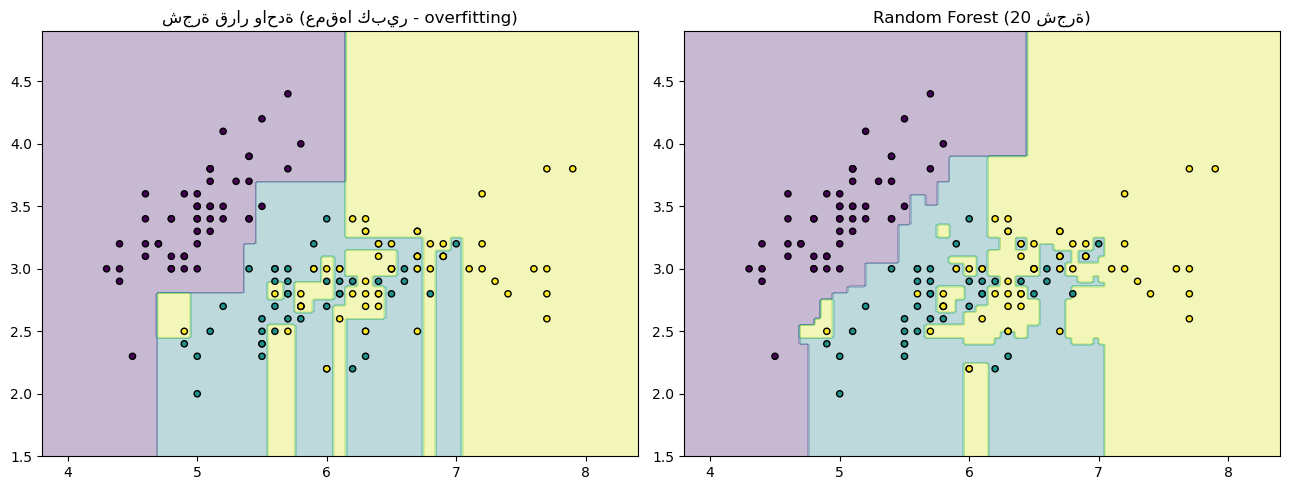

لاحظ: حدود الشجرة الواحدة متعرّجة جدًا وحادة (overfitting)
بينما حدود Random Forest أنعم وأكثر تعميمًا


In [74]:
X2 = X[: , :2]
X2_train , X2_test , y2_train , y2_test = train_test_split(X2 ,y , test_size=0.2 , random_state=42)

fig , axes = plt.subplots(1, 2, figsize=(13 , 5))

for ax, (name, model) in zip(axes, [
    ('شجرة قرار واحدة (عمقها كبير - overfitting)', DecisionTreeClassifier(max_depth=None, random_state=42)),
    ('Random Forest (20 شجرة)', RandomForestClassifier(n_estimators=20, random_state=42))
]):
    model.fit(X2_train , y2_train)

    x_min , x_max = X2[: , 0].min()-0.5 , X2[: , 0].max()+0.5
    y_min , y_max = X2[: , 1].min()-0.5 , X2[: , 1].max()+0.5

    xx , yy = np.meshgrid(np.linspace(x_min , x_max , 200) , np.linspace(y_min , y_max , 200))
    Z = model.predict(np.c_[xx.ravel() , yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx , yy ,Z ,alpha=0.3 , cmap='viridis')
    ax.scatter(X2[:,0] , X2[:, 1] , c=y , cmap='viridis' , edgecolor='k' ,s=20)
    ax.set_title(name)

plt.tight_layout()
plt.show()

print('لاحظ: حدود الشجرة الواحدة متعرّجة جدًا وحادة (overfitting)')
print('بينما حدود Random Forest أنعم وأكثر تعميمًا')